In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [2]:
# Loading the dataset")
df = pd.read_csv("/home/diego/Downloads/amz_uk_price_prediction_dataset.csv")

In [9]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
#1 Crosstab

# Generating a crosstab for 'MSZoning' and 'SaleCondition'
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [ ]:
#At first glance, products in the Women category has far more best sellers. It is followed by Women's Sport & Outdoor Shoes

In [16]:
crosstab_result.describe()

isBestSeller,False,True
count,296.000000,296.000000
mean,8228.618243,26.959459
std,48543.695707,66.877209
min,53.000000,0.000000
25%,256.000000,1.000000
50%,5218.000000,5.000000
75%,9220.750000,23.250000
max,835935.000000,556.000000


In [5]:
#1.2

from scipy.stats import chi2_contingency

# Chi-square test for 'isBestSeller' and 'category'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

#if p value is below 0.05, there is a significant association between the two variables
#The category matter for a best seller. The category a product belongs to does affect how likely it is to be a best-seller.



(np.float64(36540.20270061387), np.float64(0.0))

In [27]:
#1.3

#Crosstab with proportions and share

crosstab_top = pd.crosstab(df['category'], df['isBestSeller'], margins=True, margins_name="Total")

crosstab_top = crosstab_top.drop("Total") #remove the row Total at the botton, "grand total", not a category

crosstab_top["Share"] = crosstab_top[True] / crosstab_top["Total"]

crosstab_top = crosstab_top.sort_values(by="Share", ascending=False)


top_10 = crosstab_top.head(10)
print(top10)

#Considering the proportions (those ranked "best seller out of total (with the false, included) the picthre changes.
#Grocery, Smart Home and Health and Personal Care completes the top three

isBestSeller                       False     True 
category                                          
Grocery                         0.941865  0.058135
Smart Home Security & Lighting  0.942308  0.057692
Health & Personal Care          0.942314  0.057686
Mobile Phone Accessories        0.957529  0.042471
Power & Hand Tools              0.964661  0.035339
Billiard, Snooker & Pool        0.967871  0.032129
Pet Supplies                    0.969800  0.030200
Home Brewing & Wine Making      0.971545  0.028455
Mirrors                         0.972000  0.028000
Wind Instruments                0.972000  0.028000


In [26]:
#Top categories with most best-sellers like women


crosstab_top2 = pd.crosstab(df['category'], df['isBestSeller'], margins=True, margins_name="Total")

crosstab_top2 = crosstab_top2.drop("Total") #remove the row Total at the botton, "grand total", not a category

crosstab_top2["Share"] = crosstab_top2[True] / crosstab_top2["Total"]

crosstab_top2 = crosstab_top2.sort_values(by=True, ascending=False)


print(crosstab_top2.head(10))

isBestSeller             False  True   Total     Share
category                                              
Grocery                   9008   556    9564  0.058135
Health & Personal Care    9017   552    9569  0.057686
Baby                     14709   341   15050  0.022658
Sports & Outdoors       835935   330  836265  0.000395
Power & Hand Tools        8353   306    8659  0.035339
Beauty                   19010   302   19312  0.015638
Pet Supplies              9152   285    9437  0.030200
Arts & Crafts             9319   230    9549  0.024086
Women                    17559   213   17772  0.011985
Men                      17248   169   17417  0.009703


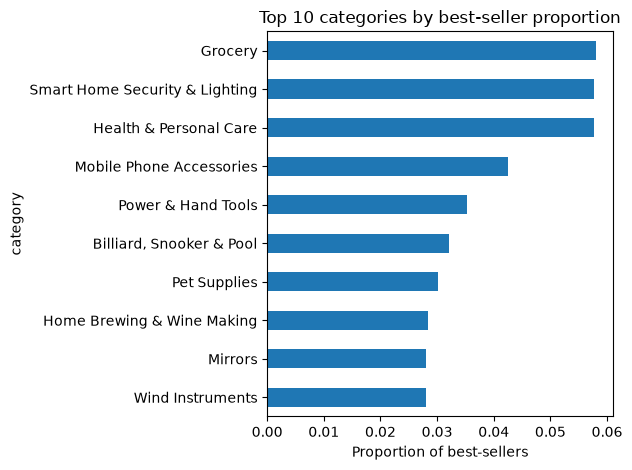

In [28]:
# 4. Plot only the best-seller proportion
top10[True].plot(kind="barh")
plt.gca().invert_yaxis() #Highest values at the top
plt.xlabel("Proportion of best-sellers")
plt.title("Top 10 categories by best-seller proportion")
plt.tight_layout()
plt.show()

In [ ]:
#2

crosstab_top2 = pd.crosstab(df['category'], df['isBestSeller'], margins=True, margins_name="Total")

crosstab_top2 = crosstab_top2.drop("Total") #remove the row Total at the botton, "grand total", not a category

crosstab_top2["Share"] = crosstab_top2[True] / crosstab_top2["Total"]

crosstab_top2 = crosstab_top2.sort_values(by=True, ascending=False)


/tmp/ipykernel_246576/4079535986.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='price', y='category', palette="coolwarm")


<Axes: xlabel='price', ylabel='category'>

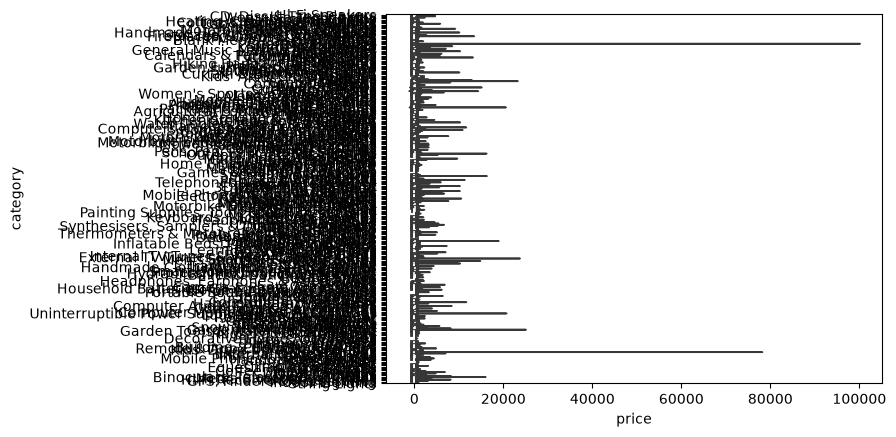

In [4]:
sns.violinplot(data=df, x='price', y='category', palette="coolwarm")

In [21]:
frequency_table = df["category"].value_counts()
#value_counts() sorts its result by default. 
#When you call it, pandas counts each unique value and then automatically orders the result from the highest count to the lowest

In [12]:
top_20_categories = frequency_table.head(20).index
df_top_20 = df[df['category'].isin(top_20_categories)] #isin means “is in”. It checks, for every value in a column, whether that value is in a list you give it. 
#It returns True or False for each row.

In [13]:
df_top_20

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


In [14]:
print(frequency_table.head())

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


In [15]:
print(df_top_20['category'].nunique())
print(len(df_top_20))

20
1182251


/tmp/ipykernel_246576/3424242428.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top_20, x='price', y='category', palette="coolwarm")


<Axes: xlabel='price', ylabel='category'>

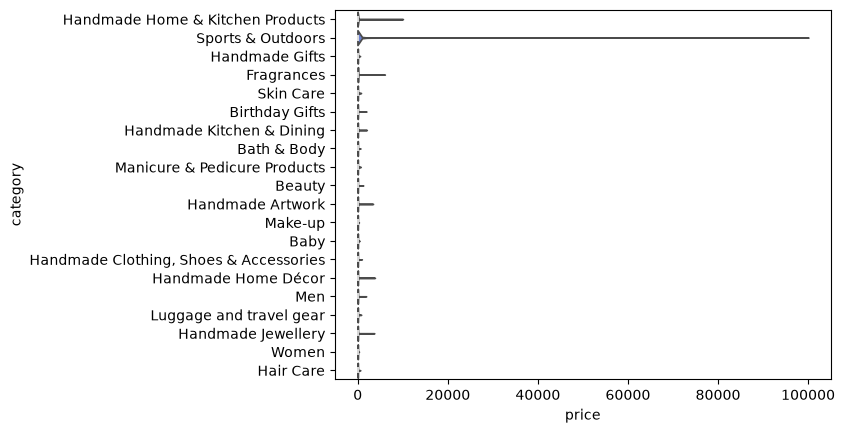

In [17]:
sns.violinplot(data=df_top_20, x='price', y='category', palette="coolwarm")

In [24]:
#2.2
top_10_categories = frequency_table.head(10).index
df_top_10 = df[df['category'].isin(top_10_categories)]
df_top_10

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
82163,89483,B07DLGZ828,Neutrade GoPro 3M Sticky Pads Double Sided Adh...,4.2,3116,6.49,False,0,Sports & Outdoors
82164,89484,B09HGZHXJT,"WOLFANG Action Camera 4K 20MP GA100, Waterproo...",4.2,2594,49.99,False,0,Sports & Outdoors
82165,89485,B08G2HBBB6,GoPro HERO9 - Waterproof Sports Camera with Fr...,4.5,5161,199.00,True,0,Sports & Outdoors
82166,89486,B09D15SFMQ,GoPro HERO10 Black - Waterproof Action Camera ...,4.4,2467,249.99,False,0,Sports & Outdoors
82167,89487,B08LD4VXGL,FitStill 60M/196FT Waterproof Case for Go Pro ...,4.5,9879,16.98,True,0,Sports & Outdoors
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


In [25]:
average_price = df_top_10.groupby("category")["price"].mean()

In [26]:
average_price

category
Bath & Body                                15.042266
Beauty                                     13.222322
Birthday Gifts                             26.585166
Fragrances                                 36.202865
Hair Care                                  14.326030
Handmade Clothing, Shoes & Accessories     16.865767
Make-up                                    10.895356
Manicure & Pedicure Products               10.521108
Skin Care                                  16.340926
Sports & Outdoors                         125.769814
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='category'>

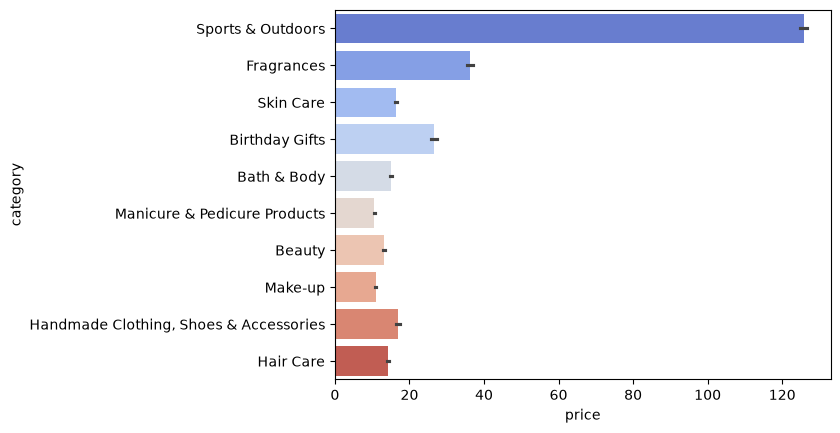

In [31]:
sns.barplot(data=df_top_10, x='price', y='category', hue="category", palette="coolwarm", legend=False)

<Axes: xlabel='reviews', ylabel='category'>

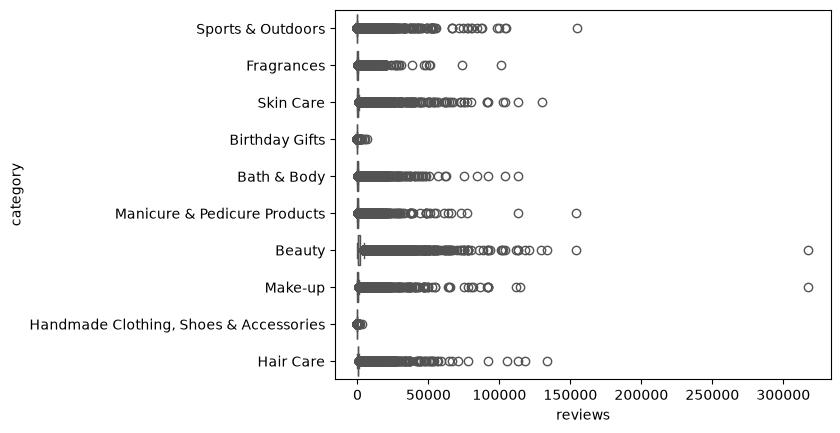

In [36]:
#3
sns.boxplot(data=df_top_10, x='reviews', y='category', hue="category", palette="coolwarm", legend=False)

In [ ]:
#3

In [39]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

In [40]:
df["price"].corr(df["stars"]) #The relationship is not strong, but weak - The correlation coefficient is nowhere near -1 and 1

np.float64(-0.12490673262159065)

In [41]:
#3.2

In [ ]:
#Visualisation

<Axes: xlabel='price', ylabel='reviews'>

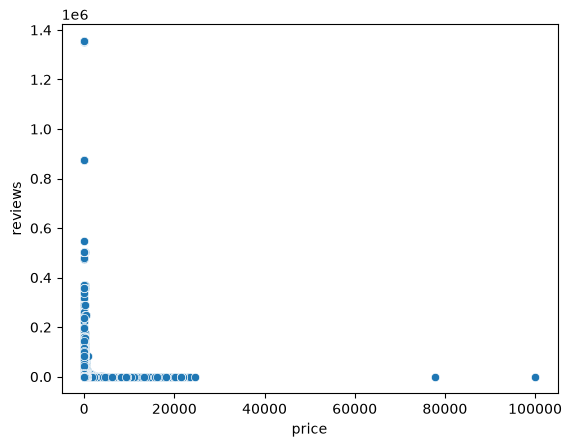

In [42]:
# Plotting a scatter plot to visualize the relationship between 'reviews' and 'price'
sns.scatterplot(data=df, x='price', y='reviews')

In [45]:
df_numerical = df.select_dtypes("number") #It filters a Pandas DataFrame to keep only the numeric columns.
df_numerical.corr() #Calculating the correlation of everything

,uid,stars,reviews,price,boughtInLastMonth
uid,1.000000,0.031696,0.019994,0.008273,0.016336
stars,0.031696,1.000000,0.085808,-0.124907,0.112536
reviews,0.019994,0.085808,1.000000,-0.013171,0.104043
price,0.008273,-0.124907,-0.013171,1.000000,-0.023439
boughtInLastMonth,0.016336,0.112536,0.104043,-0.023439,1.000000


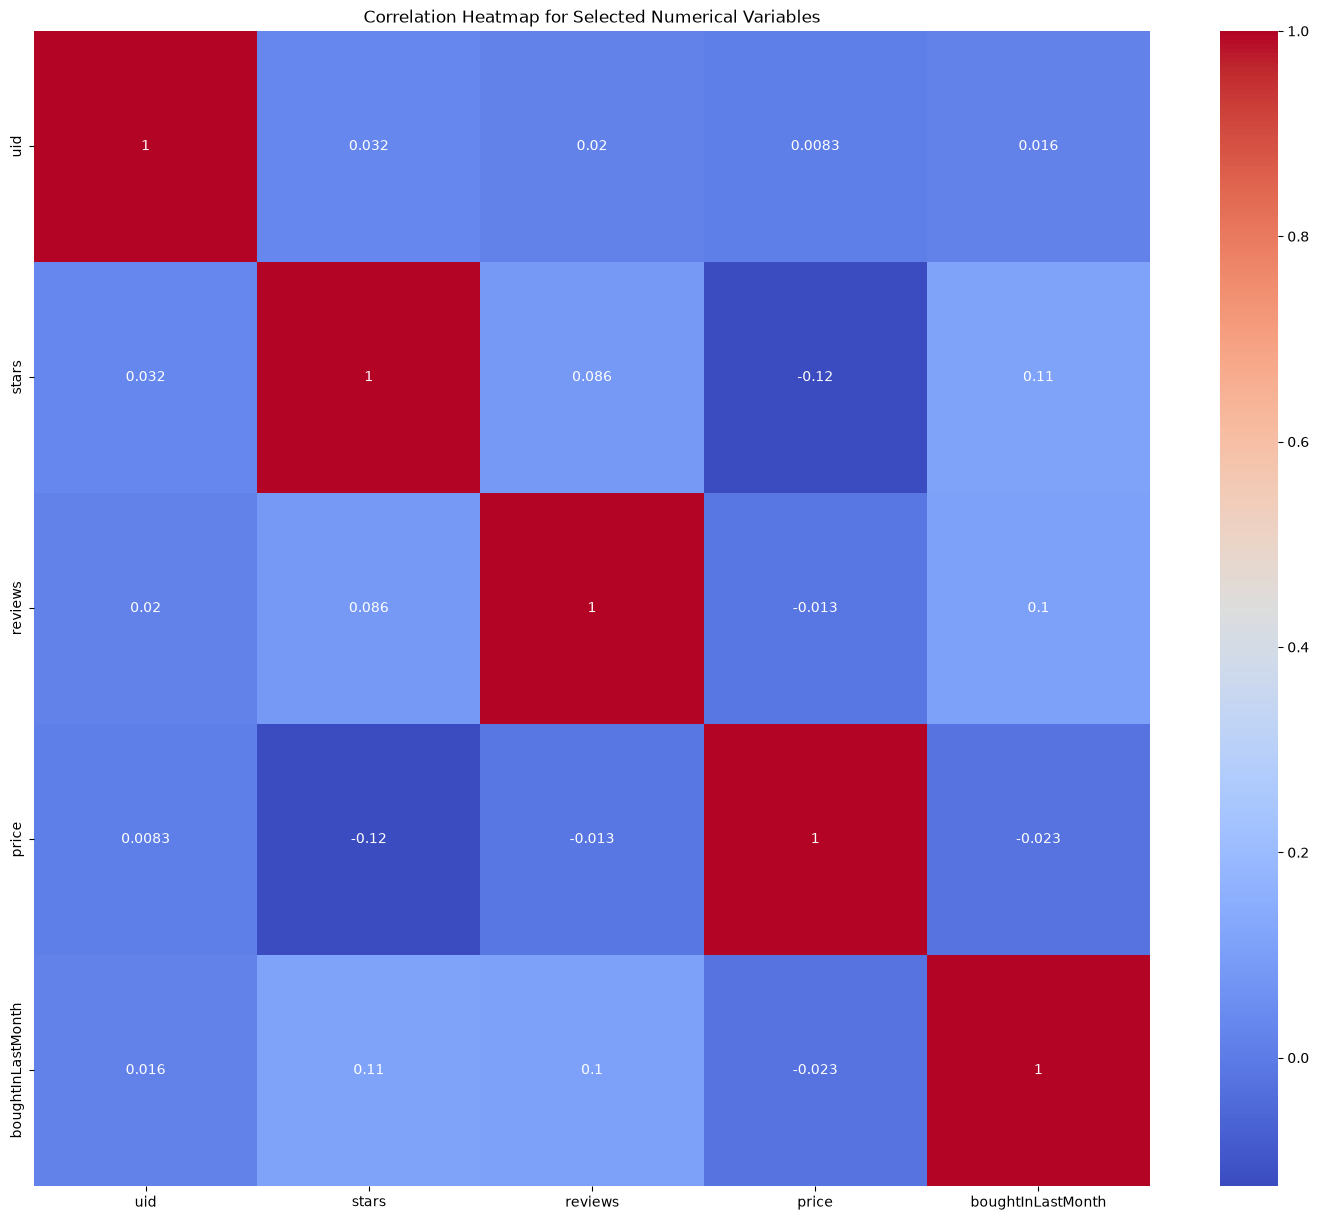

In [46]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()